# Lab6A: Dyna-Q vs Dyna-Q + in modify Figure 8.2 in [Sutton & Barto]

This lab reproduces modify **Figure 8.2** from *Reinforcement Learning: An Introduction*
(Sutton & Barto, Chapter 8).

We study **Dyna-Q** and **Dyna-Q +** in a simple deterministic maze and we compare how they would react to a changement of environement.

You will:
- Build the **Dyna Maze** (46 states)
- Implement a **Dyna-Q algorithm**
- Implement a **Dyna-Q + algorithm**
- Change environement at a time T
- Understand *what* changes in learning


In [33]:
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass
from typing import Dict, Tuple, List


## 1. Experimental setup

- Discount factor: $\gamma = 0.95$
- Learning rate: $\alpha = 0.1$
- Exploration: $\varepsilon = 0.1$ for $\varepsilon$-greedy.
- Reward:
  - `+1` when entering the goal state
  - `0` otherwise
- Environment:
  - Deterministic transitions
  - Grid world with obstacles (46 states total)

These choices match the RL book setup for Figure 8.2 in [Sutton & Barto].


**Exercise 1.** (The Dyna Maze Environment) Implement the maze used in Figure 8.2 and understand the code.

The maze:
- Is a 6×9 grid (54 cells)
- Contains **8 obstacles**, leaving **46 valid states**
- The obstacles changes place at a time T
- Has four actions: up, right, down, left
- If an action would hit a wall or obstacle, the agent **stays in place**
- Reward is +1 **only when entering the goal cell**

In [34]:
@dataclass
class DynaMazeEnv:
    rows: int = 6
    cols: int = 9
    gamma: float = 0.95

    T: int = 1000

    action_moves = {
        0: (-1, 0),
        1: (0,  1),
        2: (1,  0),
        3: (0, -1),
    }

    def __post_init__(self):
        self.time_step = 0

        # Initial wall configuration
        self.walls = {(3, c) for c in range(9)}

        self.start_rc = (2, 0)
        self.goal_rc = (0, 8)

        self._build_states()
        self.reset()

    def _build_states(self):
        self.rc_to_s = {}
        self.s_to_rc = {}

        s = 0
        for r in range(self.rows):
            for c in range(self.cols):
                if (r, c) in self.walls:
                    continue

                self.rc_to_s[(r, c)] = s
                self.s_to_rc[s] = (r, c)
                s += 1

        self.n_states = s
        self.n_actions = 4

    def reset(self):
        self.state = self.rc_to_s[self.start_rc]
        return self.state

    def step(self, action):

        # Check whether it is time to change the wall
        if self.time_step >= self.T:
            self.walls = {(2, c) for c in range(1, 9)}
            self._build_states()

        r, c = self.s_to_rc[self.state]

        dr, dc = self.action_moves[action]
        nr, nc = r + dr, c + dc

        if (
            nr < 0 or nr >= self.rows or
            nc < 0 or nc >= self.cols or
            (nr, nc) in self.walls
        ):
            nr, nc = r, c

        next_state = self.rc_to_s[(nr, nc)]

        reward = 1.0 if (nr, nc) == self.goal_rc else 0.0
        done = (nr, nc) == self.goal_rc

        self.state = next_state
        self.time_step += 1

        return next_state, reward, done

**Exercise 2.** (Implement Dyna-Q) Implement a **tabular Dyna-Q algorithm**:

Algorithm structure:
1. Select action using $\varepsilon$-greedy with fair tie-breaking.
2. Take real step in environment
3. Q-learning update
4. Store transition in the model
5. Perform `n` planning updates by sampling from the model

In [35]:
def epsilon_greedy_action(Q_row, eps, rng): # This implements an ε-greedy policy. Here, Q_row is the vector Q(s, .) for a fixed state s.
    if rng.random() < eps :  # With probability epsilon: explore (choose a random action)
        return int(rng.integers(0, len(Q_row)))  # With probability 1−ε: exploit (choose an action with the highest estimated value)
    maxv = np.max(Q_row)  # Finds the maximum Q-value among actions.
    best = np.flatnonzero(Q_row == maxv)  #  here can be ties, means several actions have the same Q value,
    # Q_row == maxv gives a boolean array like [True, False, True, ...]
    # np.flatnonzero(...) returns the indices where it’s True (a 1D array), e.g. [0, 2]
    return int(rng.choice(best)) # If multiple best actions exist, pick one uniformly at random and this prevents a systematic bias like always choosing the smallest index action.

class DynaQAgent:  # Now we define a learning agent that implements the Dyna-Q algorithm.
    def __init__(self, n_states, n_actions, alpha=0.1, gamma=0.95, eps=0.1, planning_steps=5, rng=None):
        self.Q = np.zeros((n_states, n_actions)) # This is the aabular Q-learning table with rows = states and columns = actions,
                                                 # Initially all values are 0
        self.alpha = alpha # alpha = learning rate (step size) for Q updates.
        self.gamma = gamma # gamma = discount factor used in TD target.
        self.eps = eps # eps = epsilon for epsilon-greedy exploration.
        self.n = planning_steps # This is the “n” in Dyna-Q: number of planning updates per real step.
        self.rng = rng or np.random.default_rng() # If we provide a random generator, use it (for reproducibility), otherwise, creat a new one.

        self.model = {} # This is the learned model is stored as a dictionary, with Key: (s, a) and value: (r, s'). Here we assume that the maze dynamics are deterministic.
        self.observed_sa = [] # A list of all (s,a) pairs that have been seen at least once.
                              # Used so planning can sample only from experienced pairs (instead of impossible ones).

    def act(self, s):  # act = action selection
        return epsilon_greedy_action(self.Q[s], self.eps, self.rng)  # self.Q[s] extracts the row vector Q(s, :) (the value of actions for state s) then we pass it to epsilon-greedy.

    def q_update(self, s, a, r, sp):  # this is Q-learning update
        td_target = r + self.gamma * np.max(self.Q[sp])  # sp here means s'
        self.Q[s, a] += self.alpha * (td_target - self.Q[s, a])  #  Q-learning update

    def observe(self, s, a, r, sp): # observe = where Dyna happens, which is called after the agent takes an action in the real environment and receives the transition (s,a,r,s')
        # Direct RL update
        self.q_update(s, a, r, sp)  # Direct RL update : this is learning from real experience (interaction with the environment).

        # Model update = this is learning from simulated experience
        key = (s, a) # key identifies the state-action pair.
        if key not in self.model: # If this (s,a) has never been seen,
            self.observed_sa.append(key) # record it in observed_sa so planning can use it.
        self.model[key] = (r, sp) # Now we update the model : “If in state s take action a, we will get reward r and go to state sp.”

        # Planning = This is the “Dyna” part.
        for _ in range(self.n): # for each planning step (n steps in total)
            ss, aa = self.observed_sa[int(self.rng.integers(len(self.observed_sa)))]   # Sample a previously observed (s,a) pair uniformly at random
            rr, ssp = self.model[(ss,aa)]  # Use the model to retrieve its predicted reward and next state (rr, ssp). Hint. use self.model[key], what is the key here ?
            self.q_update(ss,aa,rr,ssp)   # Apply the same Q-learning update as if it were a real transition. Hint. use self.q_update(ss, aa, rr, ssp)

**Exercise 3.** (Implement Dyna-Q+) Implement a **tabular Dyna-Q+ algorithm**:

Algorithm structure:
1. Select action using $\varepsilon$-greedy with fair tie-breaking.
2. Keep a track of all the last time a (state, action) is executed
3. Take real step in environment
4. Modify the reward to add a bonus in exploring old step
5. Q-learning update
6. Store transition in the model
7. Perform `n` planning updates by sampling from the model

In [36]:
class DynaQpAgent:
    def __init__(self, n_states, n_actions, alpha=0.1, gamma=0.95, eps=0.1, planning_steps=5, kappa=1e-4, rng=None):
        self.Q = np.zeros((n_states, n_actions))
        self.alpha = alpha
        self.gamma = gamma
        self.eps = eps
        self.n = planning_steps
        self.kappa = kappa
        self.rng = rng or np.random.default_rng()

        self.n_states = n_states
        self.n_actions = n_actions

        # In Dyna-Q+, we initialize the model for all state-action pairs.
        # Initially, the model assumes each transition leads back to the same state with 0 reward.
        self.model = {}
        for s in range(self.n_states):
            for a in range(self.n_actions):
                self.model[(s, a)] = (0.0, s)

        # Keep track of the last time step each state-action pair was tried.
        # Initialized to 0.
        self.tau = np.zeros((n_states, n_actions))
        self.time_step = 0

    def act(self, s):
        return epsilon_greedy_action(self.Q[s], self.eps, self.rng)

    def q_update(self, s, a, r, sp):
        td_target = r + self.gamma * np.max(self.Q[sp])
        self.Q[s, a] += self.alpha * (td_target - self.Q[s, a])

    def observe(self, s, a, r, sp):
          self.time_step += 1
          self.tau += 1
          self.tau[s, a] = 0  # reset elapsed time for the selected (s, a) pair

          # Direct RL update
          self.q_update(s, a, r, sp)

          # Model update
          self.model[(s, a)] = (r, sp)

          # Planning step
          # In Dyna-Q+, planning samples from ALL possible state-action pairs
          for _ in range(self.n):
              ss = int(self.rng.integers(0, self.n_states))
              aa = int(self.rng.integers(0, self.n_actions))

              rr, ssp = self.model[(ss, aa)]

              # Add exploration bonus: kappa * sqrt(tau)
              bonus_reward = rr + self.kappa * np.sqrt(self.tau[ss, aa])
              self.q_update(ss, aa, bonus_reward, ssp)

**Exercise 4.** Reproduce Figure 8.2

Run the experiment:
- Compare for 1000 step the average performance of **Dyna-Q** and **Dyna-Q+** algorithm
- Plot **cumulative reward vs Time step**

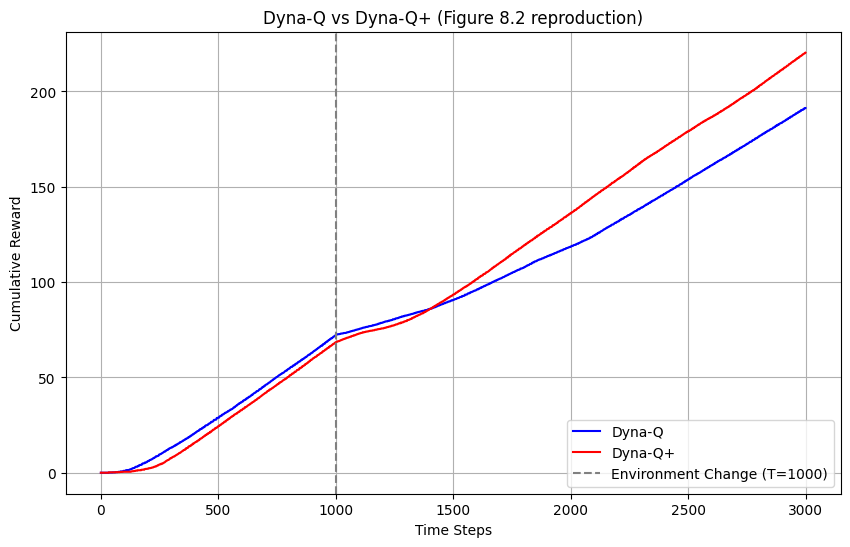

In [37]:
def run_experiment(agent_class, planning_steps=50, total_steps=3000, n_runs=10, **agent_kwargs):
    # We track cumulative reward at each step, averaged over multiple independent runs
    cumulative_rewards = np.zeros((n_runs, total_steps))

    for run in range(n_runs):
        # Initialize environment
        env = DynaMazeEnv()
        env.T = 1000  # Wall configuration changes at T=1000

        # Initialize agent
        rng = np.random.default_rng(run)
        agent = agent_class(
            n_states=env.n_states,
            n_actions=env.n_actions,
            planning_steps=planning_steps,
            rng=rng,
            **agent_kwargs
        )

        s = env.reset()
        cum_r = 0
        for step in range(total_steps):
            a = agent.act(s)
            sp, r, done = env.step(a)

            # Dynamic resizing to handle changes in the environment states
            max_state_needed = max(s, sp)
            if max_state_needed >= agent.Q.shape[0]:
                new_size = max_state_needed + 1
                # Pad Q-table with zeros
                padding = np.zeros((new_size - agent.Q.shape[0], agent.Q.shape[1]))
                agent.Q = np.vstack([agent.Q, padding])
                # Update DynaQ+ specific structures if the agent is Dyna-Q+
                if hasattr(agent, 'tau'):
                    tau_padding = np.zeros((new_size - agent.tau.shape[0], agent.tau.shape[1]))
                    agent.tau = np.vstack([agent.tau, tau_padding])
                    agent.n_states = new_size
                    # Initialize new state transitions in Dyna-Q+ model
                    for state_idx in range(agent.Q.shape[0] - padding.shape[0], new_size):
                        for act_idx in range(agent.n_actions):
                            if (state_idx, act_idx) not in agent.model:
                                agent.model[(state_idx, act_idx)] = (0.0, state_idx)

            agent.observe(s, a, r, sp)

            cum_r += r
            cumulative_rewards[run, step] = cum_r

            if done:
                s = env.reset()
            else:
                s = sp

    return np.mean(cumulative_rewards, axis=0)

# Run the simulations with 50 planning steps (matching Figure 8.2 in the book)
total_steps = 3000
n_runs = 10
planning_steps = 50


dyna_q_rewards = run_experiment(DynaQAgent, planning_steps=planning_steps, total_steps=total_steps, n_runs=n_runs)
dyna_qp_rewards = run_experiment(DynaQpAgent, planning_steps=planning_steps, total_steps=total_steps, n_runs=n_runs, kappa=1e-3)

# Plotting the results
plt.figure(figsize=(10, 6))
plt.plot(dyna_q_rewards, label="Dyna-Q", color='blue')
plt.plot(dyna_qp_rewards, label="Dyna-Q+", color='red')
plt.axvline(x=1000, color='gray', linestyle='--', label='Environment Change (T=1000)')
plt.xlabel("Time Steps")
plt.ylabel("Cumulative Reward")
plt.title("Dyna-Q vs Dyna-Q+ (Figure 8.2 reproduction)")
plt.legend()
plt.grid(True)
plt.show()

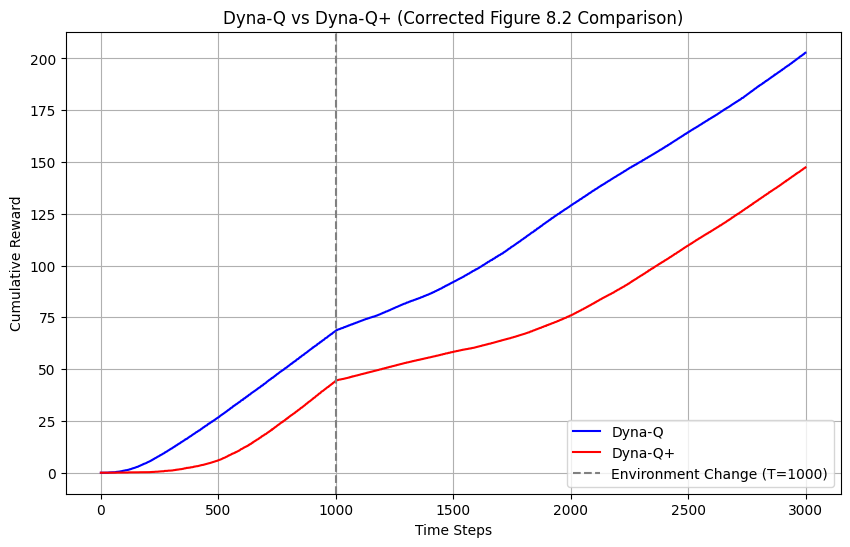

In [38]:
T = 3000
n_runs = 30
alpha = 0.1
gamma = 0.9
epsilon = 0.1
n_plan = 10
kappa = 1e-4
step_penalty=-0.01
goal_reward=4.0

# Exécuter les expériences avec vos paramètres
dyna_q_rewards = run_experiment(
    DynaQAgent,
    planning_steps=n_plan,
    total_steps=T,
    n_runs=n_runs,
    alpha=alpha,
    gamma=gamma,
    eps=epsilon
)

dyna_qp_rewards = run_experiment(
    DynaQpAgent,
    planning_steps=n_plan,
    total_steps=T,
    n_runs=n_runs,
    alpha=alpha,
    gamma=gamma,
    eps=epsilon,
    kappa=kappa
)

# Tracer le graphique comparatif
plt.figure(figsize=(10, 6))
plt.plot(dyna_q_rewards, label="Dyna-Q", color='blue')
plt.plot(dyna_qp_rewards, label="Dyna-Q+", color='red')
plt.axvline(x=1000, color='gray', linestyle='--', label='Environment Change (T=1000)')
plt.xlabel("Time Steps")
plt.ylabel("Cumulative Reward")
plt.title("Dyna-Q vs Dyna-Q+ (Corrected Figure 8.2 Comparison)")
plt.legend()
plt.grid(True)
plt.show()